# 06 - Threshold experiments

**Questions (guide, experiments 1 and 2):** how do the confidence threshold and the NMS IoU threshold change what the detector returns, and when does NMS become too aggressive?

Setup for every number below: YOLOv8n (COCO weights, no training), 640 px, 1,000 VOC2007-test images (seed 0), clean images, our own NMS and evaluator. Only one setting is changed at a time; the other is fixed (confidence study: NMS 0.5; NMS study: confidence 0.25).

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
FIG = os.path.abspath("../figures"); RES = os.path.abspath("../results")
os.makedirs(FIG, exist_ok=True); os.makedirs(RES, exist_ok=True)
VOC = os.path.abspath("../data/VOCdevkit/VOC2007")
from src.experiments import *
from src.evaluation import Evaluator
from src.analysis import analyse_errors
ids, gts = load_gts(); cands = load_candidates("clean_640")

## Experiment 1 - confidence threshold

Kept detections = score >= threshold, then NMS (IoU 0.5). Precision / recall are computed at that operating point. `map50_truncated` is the AP of the **truncated** ranked list: a high threshold removes the low-confidence tail of the PR curve, so recall can never reach its full value and AP falls.

In [2]:
df1 = conf_sweep(cands, gts, (0.10, 0.25, 0.50, 0.75), nms_iou=0.5)
df1.to_csv(f"{RES}/confidence_threshold_results.csv", index=False); display(df1.round(4))

,conf,n_det,tp,fp,fn,precision,recall,f1,dets_per_img,map50_truncated
0,0.10,4330,2176,2154,246,0.5025,0.8984,0.6445,4.695,0.8030
1,0.25,2853,2027,826,395,0.7105,0.8369,0.7685,3.132,0.7640
2,0.50,2017,1772,245,650,0.8785,0.7316,0.7984,2.177,0.6792
3,0.75,1233,1190,43,1232,0.9651,0.4913,0.6512,1.278,0.4728


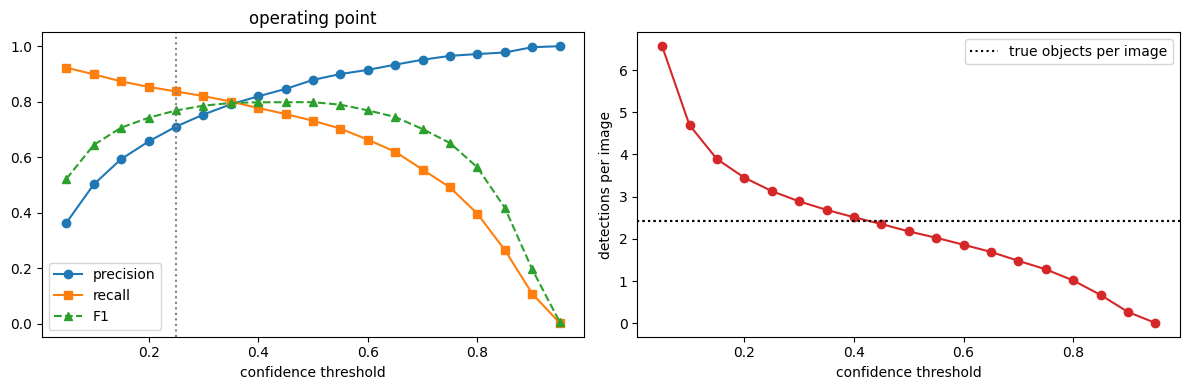

F1 is highest at confidence 0.50 (F1 0.798, precision 0.879, recall 0.732)


In [3]:
fine = np.round(np.arange(0.05, 0.96, 0.05), 2)
dff = conf_sweep(cands, gts, tuple(fine), 0.5)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(dff.conf, dff.precision, "o-", label="precision"); ax[0].plot(dff.conf, dff.recall, "s-", label="recall"); ax[0].plot(dff.conf, dff.f1, "^--", label="F1")
ax[0].axvline(0.25, c="gray", ls=":"); ax[0].set_xlabel("confidence threshold"); ax[0].legend(); ax[0].set_title("operating point")
ax[1].plot(dff.conf, dff.dets_per_img, "o-", c="C3"); ax[1].axhline(df1.attrs.get("g", 2.422), c="k", ls=":"); ax[1].set_xlabel("confidence threshold"); ax[1].set_ylabel("detections per image")
ax[1].axhline(np.mean([(~g["difficult"]).sum() for g in gts.values()]), c="k", ls=":", label="true objects per image"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{FIG}/confidence_threshold_sweep.png", dpi=110); plt.show()
dff.to_csv(f"{RES}/confidence_threshold_fine_sweep.csv", index=False)
best = dff.loc[dff.f1.idxmax()]; print(f"F1 is highest at confidence {best.conf:.2f} (F1 {best.f1:.3f}, precision {best.precision:.3f}, recall {best.recall:.3f})")

## Experiment 2 - NMS IoU threshold

Confidence fixed at 0.25. `duplicate_fp` counts false positives that sit on an object already found by a better box (what NMS is supposed to remove). `crowded_person_recall` is the recall for *people* in images that contain >= 4 people (where neighbouring boxes overlap most: aggressive NMS should hurt there). `map50_conf0_01` is mAP@50 with the full ranked list for each NMS setting.

In [4]:
df2 = nms_sweep(cands, gts, (0.3, 0.5, 0.7, None), conf=0.25)
df2.to_csv(f"{RES}/nms_threshold_results.csv", index=False); display(df2.round(4))

,nms_iou,n_det,tp,fp,fn,precision,recall,f1,dets_per_img,duplicate_fp,crowded_person_recall,crowded_person_gt,n_crowded_images,map50_conf0_01
0,0.3,2758,1993,765,429,0.7226,0.8229,0.7695,3.030,1,0.8556,367,63,0.8109
1,0.5,2853,2027,826,395,0.7105,0.8369,0.7685,3.132,13,0.8937,367,63,0.8271
2,0.7,3033,2037,996,385,0.6716,0.8410,0.7468,3.330,131,0.8992,367,63,0.8218
3,off,22981,2052,20929,370,0.0893,0.8472,0.1616,25.019,16636,0.9128,367,63,0.2106


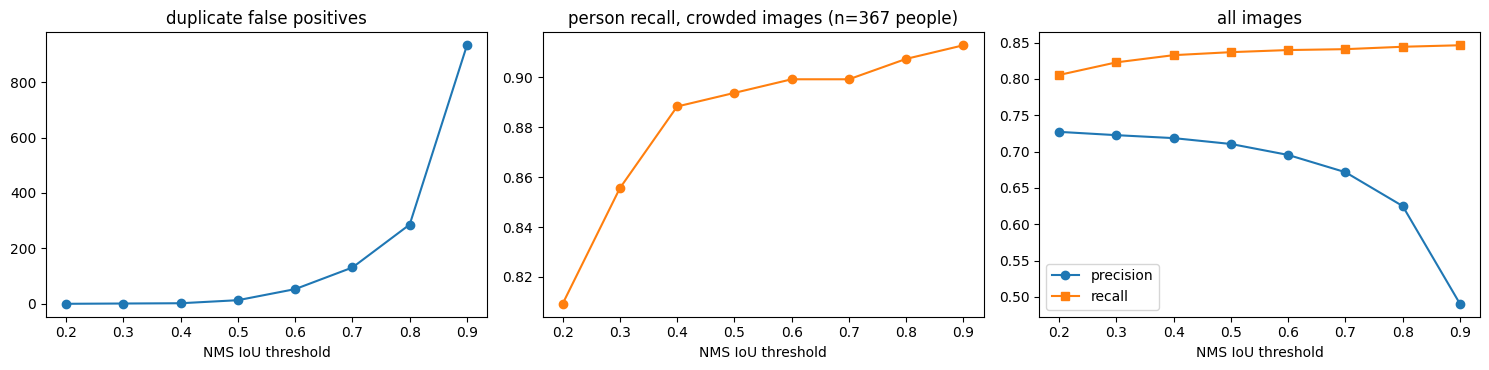

In [5]:
fine_n = (0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9)
dfn = nms_sweep(cands, gts, fine_n, conf=0.25)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(dfn.nms_iou.astype(float), dfn.duplicate_fp, "o-"); ax[0].set_title("duplicate false positives"); 
ax[1].plot(dfn.nms_iou.astype(float), dfn.crowded_person_recall, "o-", c="C1"); ax[1].set_title(f"person recall, crowded images (n={int(dfn.crowded_person_gt[0])} people)")
ax[2].plot(dfn.nms_iou.astype(float), dfn.precision, "o-", label="precision"); ax[2].plot(dfn.nms_iou.astype(float), dfn.recall, "s-", label="recall"); ax[2].legend(); ax[2].set_title("all images")
for a in ax: a.set_xlabel("NMS IoU threshold")
plt.tight_layout(); plt.savefig(f"{FIG}/nms_threshold_sweep.png", dpi=110); plt.show(); dfn.to_csv(f"{RES}/nms_threshold_fine_sweep.csv", index=False)

## Joint grid: confidence x NMS threshold

The two settings interact, so the full grid (F1 at the operating point; precision and recall in the CSV).

In [6]:
rows = []
for cth in (0.10, 0.25, 0.50, 0.75):
    for nth in (0.3, 0.5, 0.7, None):
        m = Evaluator(gts, detections(cands, cth, nth)).metrics(0.5)
        rows.append(dict(conf=cth, nms_iou="off" if nth is None else nth, precision=m["precision"], recall=m["recall"], f1=m["f1"], n_det=m["n_det"]))
grid = pd.DataFrame(rows); grid.to_csv(f"{RES}/threshold_results.csv", index=False)
display(grid.pivot(index="conf", columns="nms_iou", values="f1").round(3)); display(grid.pivot(index="conf", columns="nms_iou", values="precision").round(3)); display(grid.pivot(index="conf", columns="nms_iou", values="recall").round(3))

nms_iou,0.3,0.5,0.7,off
conf,,,,
0.10,0.663,0.645,0.585,0.120
0.25,0.769,0.769,0.747,0.162
0.50,0.794,0.798,0.795,0.199
0.75,0.648,0.651,0.651,0.229


nms_iou,0.3,0.5,0.7,off
conf,,,,
0.10,0.534,0.503,0.433,0.064
0.25,0.723,0.710,0.672,0.089
0.50,0.878,0.879,0.869,0.115
0.75,0.965,0.965,0.965,0.149


nms_iou,0.3,0.5,0.7,off
conf,,,,
0.10,0.873,0.898,0.902,0.907
0.25,0.823,0.837,0.841,0.847
0.50,0.725,0.732,0.732,0.735
0.75,0.488,0.491,0.491,0.491


## Observation (numbers are produced by the cells above and printed here)

In [7]:
o = df1.set_index("conf"); n = df2.set_index("nms_iou")
display(Markdown(f"""
**Confidence.** Raising the threshold from 0.10 to 0.75 cuts detections per image from {o.dets_per_img[0.10]:.2f} to {o.dets_per_img[0.75]:.2f}
(true objects per image: {np.mean([(~g['difficult']).sum() for g in gts.values()]):.2f}), precision goes {o.precision[0.10]:.3f} -> {o.precision[0.75]:.3f} and recall {o.recall[0.10]:.3f} -> {o.recall[0.75]:.3f}.
F1 peaks at {best.conf:.2f}. mAP@50 of the truncated list falls from {o.map50_truncated[0.10]:.3f} to {o.map50_truncated[0.75]:.3f}, which is why mAP should be computed with a very low threshold.

**NMS.** Without NMS there are {n.dets_per_img['off']:.1f} boxes per image and {int(n.duplicate_fp['off'])} duplicate false positives; with IoU 0.5 only {n.dets_per_img[0.5]:.2f} boxes and {int(n.duplicate_fp[0.5])} duplicates.
Moving 0.3 -> 0.7 changes duplicates from {int(n.duplicate_fp[0.3])} to {int(n.duplicate_fp[0.7])} and crowded-scene person recall from {n.crowded_person_recall[0.3]:.3f} to {n.crowded_person_recall[0.7]:.3f}
({int(n.crowded_person_gt[0.3])} people in {int(n.n_crowded_images[0.3])} crowded images, so that last comparison is based on a small sample).
"""))


**Confidence.** Raising the threshold from 0.10 to 0.75 cuts detections per image from 4.70 to 1.28
(true objects per image: 2.42), precision goes 0.503 -> 0.965 and recall 0.898 -> 0.491.
F1 peaks at 0.50. mAP@50 of the truncated list falls from 0.803 to 0.473, which is why mAP should be computed with a very low threshold.

**NMS.** Without NMS there are 25.0 boxes per image and 16636 duplicate false positives; with IoU 0.5 only 3.13 boxes and 13 duplicates.
Moving 0.3 -> 0.7 changes duplicates from 1 to 131 and crowded-scene person recall from 0.856 to 0.899
(367 people in 63 crowded images, so that last comparison is based on a small sample).


Reading the output above: NMS is not free. A lower threshold removes more duplicates but starts deleting correct detections of touching objects (crowded images); a higher threshold keeps those objects but lets duplicates through. Because the two thresholds act on different things (confidence on individual scores, NMS on overlap between boxes) they have to be tuned together, as the grid shows.